# APID 2 exploration

APID 2 is the most popular APID in the dumps. Questions for this notebook:

1. What kinds of packets does it carry, and how are they laid out?
2. How do their timestamps relate to the SWAP image timestamps (APID 20)?
3. Is there anything in it that looks like **LYRA** data (4 broad-band channels, up to 100 Hz, counts or Hz), or
   housekeeping of it (temperatures, voltages, integration time)?
4. Does it hold attitude / pointing (a quaternion or a sun vector), which APID 20 never gave us?

In [1]:
from collections import Counter, defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from cadu import iter_packets, packet_apid, packet_sequence_count

In [2]:
CADU_DIR = Path("cadus")
APID = 2

# Layout of a packet, as found below: 6 byte primary header, then a PUS-like secondary header (version byte, service
# type, subtype), a 2 byte marker and a 6 byte time, 4 zero bytes and a structure id byte; the data follows.
SERVICE_OFFSET = 7
MARKER_OFFSET = 9
TIME_OFFSET = 11  # 4 byte big-endian tick counter, followed by a 2 byte fraction
SID_OFFSET = 21
DATA_OFFSET = SID_OFFSET + 1
HOUSEKEEPING = bytes([3, 25])  # service 3, subtype 25: housekeeping parameter report
MARKER = b"\x00\x01"

MAX_TICK_SPREAD = 10_000_000  # packets reassembled across lost frames have garbage where the time should be
MIN_CLASS_SIZE = 50  # structures with fewer packets are skipped by the column scans
TOP_N = 15

## 1. Load

One pass over the dumps keeps the APID 2 packets.

In [3]:
packets: list[tuple[str, int, bytes]] = []  # (file name, vcid, packet)

for path in sorted(CADU_DIR.glob("*.cadu")):
    packets += [(path.name, vcid, packet) for vcid, packet in iter_packets(path) if packet_apid(packet) == APID]
    print(f"processed {path.name}")

print(f"{len(packets)} packets with APID {APID}")

processed proba2_dump(1).cadu
processed proba2_dump(10).cadu
processed proba2_dump(11).cadu
processed proba2_dump(12).cadu
processed proba2_dump(2).cadu
processed proba2_dump(3).cadu
processed proba2_dump(4).cadu
processed proba2_dump(5).cadu
processed proba2_dump(6).cadu
processed proba2_dump(7).cadu
processed proba2_dump(8).cadu
processed proba2_dump(9).cadu
processed proba2_dump.cadu
18399 packets with APID 2


In [4]:
per_file = Counter(name for name, _, _ in packets)
per_vc = Counter(vcid for _, vcid, _ in packets)
print("virtual channels:", dict(per_vc))
for name, count in per_file.items():
    print(f"{name:24s} {count:6d}")

virtual channels: {1: 6113, 2: 12280, 5: 6}
proba2_dump(1).cadu        6305
proba2_dump(10).cadu       3237
proba2_dump(11).cadu        614
proba2_dump(12).cadu        694
proba2_dump(2).cadu         273
proba2_dump(3).cadu         594
proba2_dump(4).cadu         152
proba2_dump(5).cadu         219
proba2_dump(6).cadu        2505
proba2_dump(7).cadu         354
proba2_dump(8).cadu        2538
proba2_dump(9).cadu         444
proba2_dump.cadu            470


## 2. Headers

Primary header: sequence flags (3 = unsegmented), sequence count, length. Then see what the first bytes of the
data field are.

In [5]:
print("sequence flags:", Counter(packet[2] >> 6 for _, _, packet in packets))
print("first byte after the primary header:", Counter(packet[6] for _, _, packet in packets).most_common(5))

services = Counter((packet[7], packet[8]) for _, _, packet in packets)
print(f"\n(service, subtype) pairs: {len(services)} distinct")
for pair, count in services.most_common(8):
    print(f"  {pair}: {count}")
print("... and the long tail is mostly singletons:", sum(count == 1 for count in services.values()))

sequence flags: Counter({3: 18397, 2: 2})
first byte after the primary header: [(16, 18371), (17, 3), (86, 2), (21, 2), (222, 2)]

(service, subtype) pairs: 48 distinct
  (3, 25): 18064
  (1, 1): 141
  (1, 7): 139
  (3, 130): 10
  (3, 19): 2
  (143, 205): 1
  (9, 189): 1
  (203, 51): 1
... and the long tail is mostly singletons: 43


Service 3 / subtype 25 is the PUS housekeeping parameter report and covers nearly everything. The (1, 1) and (1, 7)
pairs are PUS telecommand verification reports (acceptance / completion). The singletons are not real services: they
come from packets reassembled across lost frames, so their bytes are garbage. That is also what the absurd packet
lengths are.

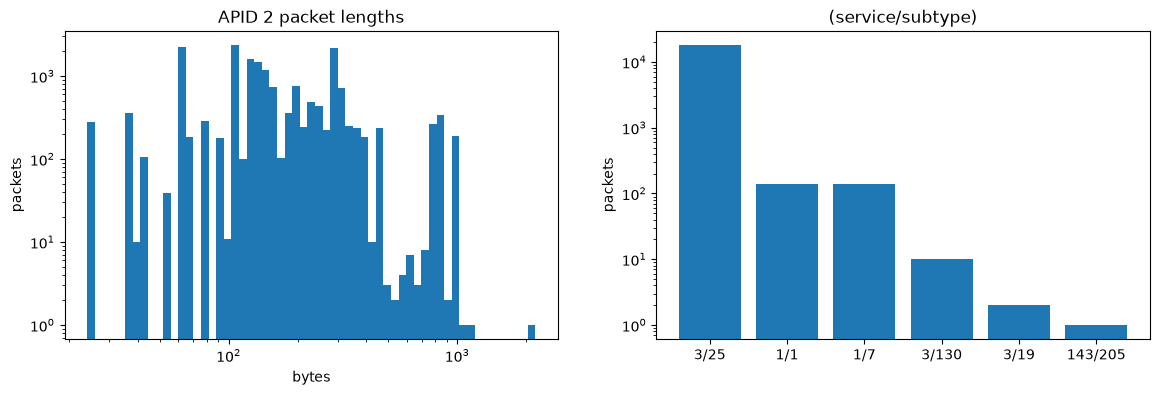

In [6]:
lengths = np.array([len(packet) for _, _, packet in packets])
fig, (ax_hist, ax_top) = plt.subplots(1, 2, figsize=(14, 4))
ax_hist.hist(lengths, bins=np.logspace(np.log10(lengths.min()), np.log10(lengths.max()), 60))
ax_hist.set(xscale="log", yscale="log", title="APID 2 packet lengths", xlabel="bytes", ylabel="packets")
top_services = services.most_common(6)
ax_top.bar([f"{s}/{t}" for (s, t), _ in top_services], [count for _, count in top_services])
ax_top.set(yscale="log", title="(service/subtype)", ylabel="packets")
plt.show()

### Lost packets

The sequence count is per APID and virtual channel, so jumps show where packets were lost (or never downlinked).

In [7]:
SEQUENCE_MODULO = 1 << 14

gaps = Counter()
by_stream: dict[tuple[str, int], list[int]] = defaultdict(list)
for name, vcid, packet in packets:
    by_stream[name, vcid].append(packet_sequence_count(packet))
for counts in by_stream.values():
    gaps.update(np.diff(counts) % SEQUENCE_MODULO)

total = sum(gaps.values())
print("sequence count step between consecutive APID 2 packets of a stream (file, vcid):")
for step, count in gaps.most_common(8):
    print(f"  {step:6d}: {count:6d} ({count / total:.1%})")

sequence count step between consecutive APID 2 packets of a stream (file, vcid):
       1:  17971 (97.8%)
       2:     89 (0.5%)
       3:     31 (0.2%)
       6:     20 (0.1%)
       4:     20 (0.1%)
       5:     17 (0.1%)
      10:     12 (0.1%)
       7:     11 (0.1%)


## 3. Housekeeping reports

A report has a structure id (SID) byte. Together with the length it identifies one fixed layout, so group by
`(length, SID)`.

In [8]:
def is_housekeeping(packet: bytes) -> bool:
    return (
        packet[SERVICE_OFFSET : SERVICE_OFFSET + 2] == HOUSEKEEPING
        and packet[MARKER_OFFSET : MARKER_OFFSET + 2] == MARKER
    )


reports = [(name, vcid, packet) for name, vcid, packet in packets if is_housekeeping(packet)]
ticks_all = np.array([int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4]) for _, _, packet in reports])
reference = np.median(ticks_all)
reports = [r for r, tick in zip(reports, ticks_all, strict=True) if abs(tick - reference) < MAX_TICK_SPREAD]
print(f"{len(reports)} housekeeping reports with a sane time (of {len(ticks_all)} that look like one)")

structures = Counter((len(packet), packet[SID_OFFSET]) for _, _, packet in reports)
print("bytes between the time and the SID:", Counter(packet[17:SID_OFFSET] for _, _, packet in reports))
print(f"{len(structures)} structures (length, SID); the biggest:")
for (length, sid), count in structures.most_common(TOP_N):
    print(f"  length {length:4d}  SID {sid:3d}  {count:5d} reports")

18044 housekeeping reports with a sane time (of 18048 that look like one)
bytes between the time and the SID: Counter({b'\x00\x00\x00\x00': 17984, b'\x00\x00\x003': 2, b'\x9f\x90\x00\x00': 1, b'\x00\x02@\x00': 1, b'lX\x90X': 1, b'M\xb0\x00\x00': 1, b'\x04\xbd\x80\x00': 1, b'_\xbb\x00\x00': 1, b'\x03\xc1g\x00': 1, b'?wX\x00': 1, b'\x003b\xa0': 1, b'\x00\x01\x9c\x00': 1, b'\xf7\xf0~@': 1, b'\x00\xa8\xce\x00': 1, b'\xae\x8c\xe29': 1, b'\x00]0\x00': 1, b'\xee&\x97\xba': 1, b'\x90\x00\x00\x00': 1, b'\x00\x00\x00\x0c': 1, b'/\xdc\x80\x00': 1, b'\x00\x00\x00\x15': 1, b'\x00\x00\x03\x9c': 1, b'\x00\x0b\x00\x00': 1, b'@\x00\x00\x05': 1, b'\x05\xee@\x00': 1, b'\xbc\x80\x00\x00': 1, b'\x00\x00Q(': 1, b'\x00g\x8a\xa4': 1, b'h\xcf\xdd\xd0': 1, b'\x00\x00\x00\x19': 1, b'\xeb\x10\x00\x00': 1, b'L\xee\xb1\x9c': 1, b'\x80\x00\x00\x00': 1, b'*\x00\x00\x00': 1, b'\x13Z9\x00': 1, b'\x00 \x00\x00': 1, b'bh\xfc@': 1, b'\x9a8\x00\x00': 1, b'\x00r9\x00': 1, b'\n\x8c\x82@': 1, b'\x00\xc83\xa0': 1, b'\x17wB\xac

## 4. Time

The 4 byte counter at offset 11 grows by a fixed step per report of a structure (2, 5, 10 ... up to 250). It is a tick
counter of **one second per tick**: `APID_18.ipynb` finds the same counter next to the GPS receiver's GPS time and
the two advance together, within a file and between the files. (A first attempt here calibrated it against the SWAP
image times, got 0.256 s per tick and was wrong: it is the SWAP times from satdump that run slow.)

0.25595 s per tick, offset 1577063996 s; residuals per file (s): [ 1670 -3404  1158   955 -3411  1219 -3479  1074  1595  1172  1491  1004
 -1045]


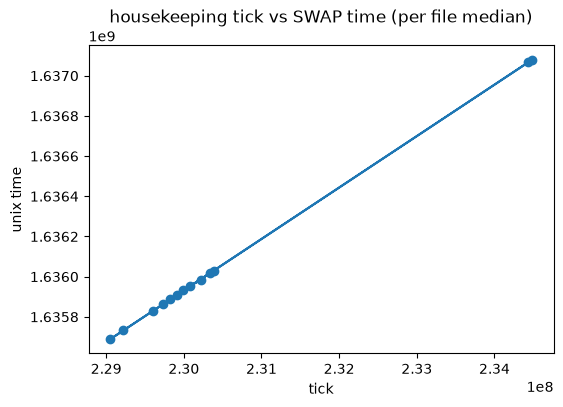

In [9]:
def report_ticks(packet: bytes) -> float:
    """Tick counter plus the 2 byte fraction after it, in seconds."""
    whole = int.from_bytes(packet[TIME_OFFSET : TIME_OFFSET + 4])
    return whole + int.from_bytes(packet[TIME_OFFSET + 4 : TIME_OFFSET + 6]) / 65536


def to_hours(ticks: np.ndarray) -> np.ndarray:
    """Hours since the first report."""
    return (ticks - reference) / 3600

## 5. Structures: which bytes change?

For every structure with enough reports, a matrix of the reports (sorted by time, duplicates from overlapping dumps
dropped). A byte whose standard deviation is 0 is constant (layout, padding); the rest is data.

In [10]:
classes: dict[tuple[int, int], dict[str, np.ndarray]] = {}
for key, count in structures.items():
    if count < MIN_CLASS_SIZE:
        continue
    members = {}
    for _, _, packet in reports:
        if (len(packet), packet[SID_OFFSET]) == key:
            members[report_ticks(packet)] = packet  # same time twice: keep one
    order = sorted(members)
    classes[key] = {
        "ticks": np.array(order),
        "bytes": np.array([np.frombuffer(members[t], dtype=np.uint8) for t in order]),
    }

print(f"{len(classes)} structures with at least {MIN_CLASS_SIZE} distinct reports")
for key, c in classes.items():
    steps = np.diff(c["ticks"])
    varying = (c["bytes"].std(axis=0) > 0).sum()
    print(f"  {key}: {len(c['ticks']):5d} reports, median step {np.median(steps):6.1f} ticks, {varying:3d} bytes vary")

44 structures with at least 50 distinct reports
  (61, 55):  2042 reports, median step   10.0 ticks,  49 bytes vary
  (104, 30):  2101 reports, median step   10.0 ticks,  87 bytes vary
  (132, 0):   900 reports, median step    5.0 ticks, 114 bytes vary
  (78, 47):   183 reports, median step  120.0 ticks,  64 bytes vary
  (384, 252):   181 reports, median step  120.0 ticks, 245 bytes vary
  (820, 250):   337 reports, median step   60.0 ticks, 781 bytes vary
  (150, 70):   644 reports, median step   30.0 ticks, 122 bytes vary
  (95, 36):   177 reports, median step  120.0 ticks,  81 bytes vary
  (64, 49):   171 reports, median step  120.0 ticks,  25 bytes vary
  (144, 52):   336 reports, median step   60.0 ticks,  94 bytes vary
  (320, 8):   705 reports, median step   30.0 ticks, 272 bytes vary
  (128, 9):   716 reports, median step   30.0 ticks, 117 bytes vary
  (292, 1):   719 reports, median step   30.0 ticks, 251 bytes vary
  (152, 7):   718 reports, median step   30.0 ticks, 124 byte

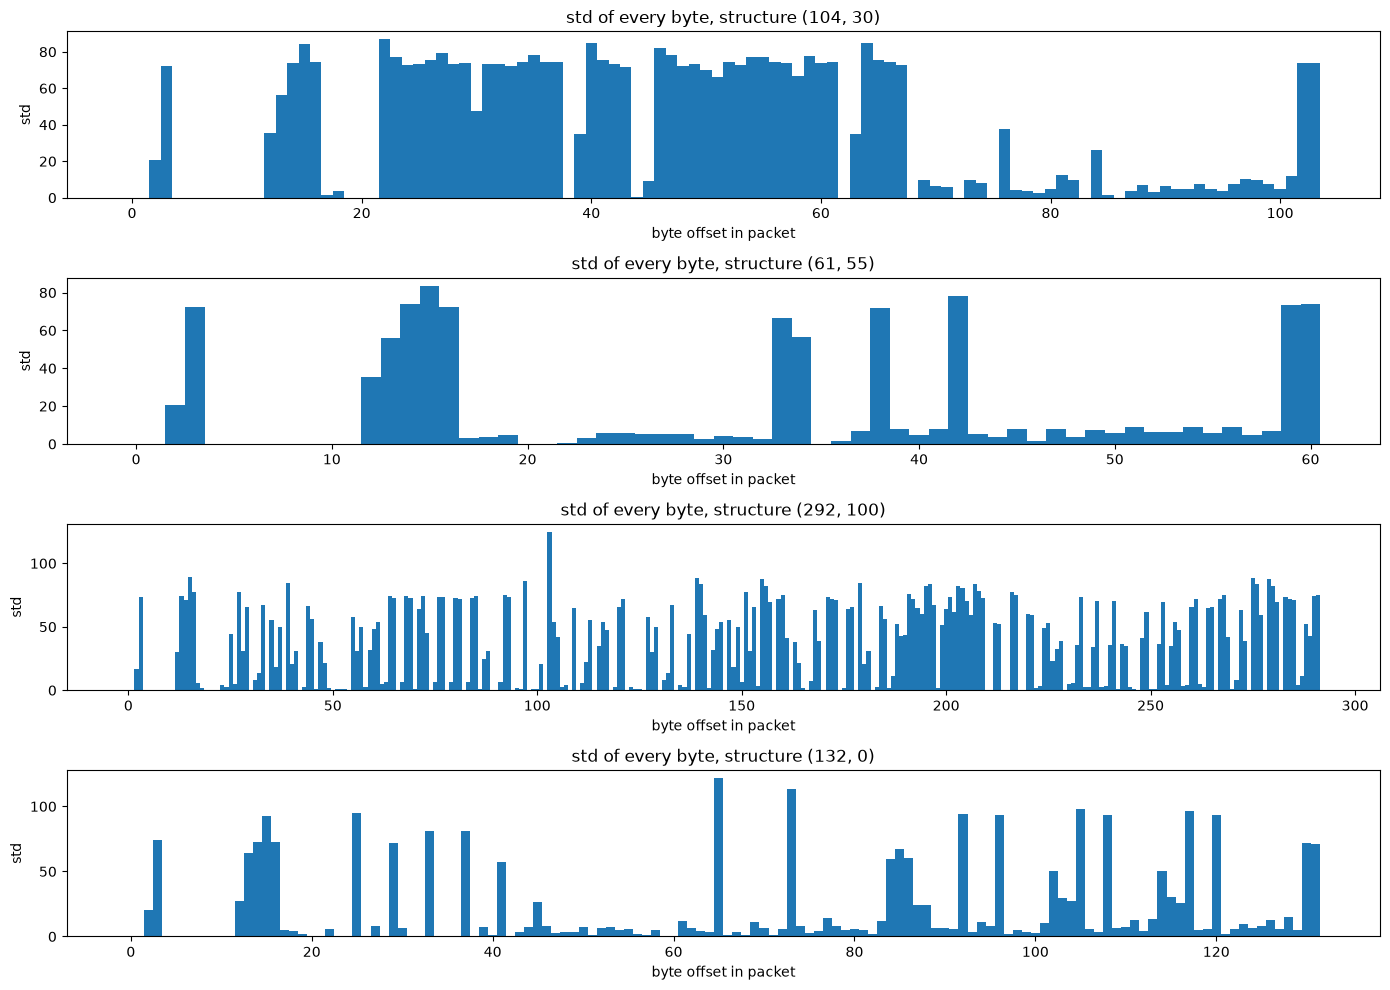

In [11]:
biggest = sorted(classes, key=lambda key: -len(classes[key]["ticks"]))[:4]
fig, axes = plt.subplots(len(biggest), 1, figsize=(14, 2.5 * len(biggest)))
for ax, key in zip(axes, biggest, strict=True):
    ax.bar(np.arange(key[0]), classes[key]["bytes"].std(axis=0), width=1.0)
    ax.set(title=f"std of every byte, structure {key}", xlabel="byte offset in packet", ylabel="std")
fig.tight_layout()
plt.show()

## 6. Column scan

Without the ICD, try every byte offset as a big-endian uint16 / int16 / uint32 / float32 and rank the resulting
series. A physical quantity (temperature, voltage, a count rate) is a slow series, so a high lag-1 autocorrelation
with real variation is what we look for. Unaligned or wrong-width reads come out as noise.

In [12]:
DTYPES = {"u2": ">u2", "i2": ">i2", "u4": ">u4", "f4": ">f4"}
MIN_UNIQUE = 10
FLOAT_RANGE = (1e-6, 1e9)  # magnitudes a float32 telemetry value can reasonably have, zero aside
MIN_AUTOCORRELATION = 0.9


def plausible(series: np.ndarray, dtype: str) -> bool:
    if not np.isfinite(series).all():
        return False
    if dtype != ">f4":
        return True
    magnitude = np.abs(series[series != 0])
    return bool(magnitude.size) and FLOAT_RANGE[0] < magnitude.min() and magnitude.max() < FLOAT_RANGE[1]


def columns(key: tuple[int, int]):
    """Yield (offset, dtype name, series) for every readable column of a structure."""
    data = classes[key]["bytes"]
    for name, dtype in DTYPES.items():
        width = np.dtype(dtype).itemsize
        for offset in range(DATA_OFFSET, key[0] - width + 1):
            series = np.ascontiguousarray(data[:, offset : offset + width]).view(dtype)[:, 0].astype(np.float64)
            if plausible(series, dtype) and len(np.unique(series)) >= MIN_UNIQUE:
                yield offset, name, series


def lag1(series: np.ndarray) -> float:
    centered = series - series.mean()
    denominator = (centered**2).sum()
    return float((centered[1:] * centered[:-1]).sum() / denominator) if denominator else 0.0


candidates = []  # (structure, offset, dtype, lag-1 autocorrelation, series)
for key in classes:
    for offset, name, series in columns(key):
        if (r := lag1(series)) > MIN_AUTOCORRELATION:
            candidates.append((key, offset, name, r, series))
print(f"{len(candidates)} slow-varying columns")

/var/folders/g2/71c5h7cs1793kf6n0mv9xmlm0000gn/T/ipykernel_7291/55033541.py:22: RuntimeWarning: invalid value encountered in cast
  series = np.ascontiguousarray(data[:, offset : offset + width]).view(dtype)[:, 0].astype(np.float64)


1764 slow-varying columns


In [13]:
# Many are the same quantity read at overlapping offsets (a float32 also reads as a plausible u2 or u4), so keep one
# read per (structure, 4 byte word), preferring float32.
best = {}
for key, offset, name, r, series in candidates:
    word = (key, offset // 4)
    if word not in best or (name == "f4" and best[word][2] != "f4"):
        best[word] = (key, offset, name, r, series)
print(f"{len(best)} distinct words")
for key, offset, name, r, series in list(best.values())[:40]:
    print(f"structure {key}  offset {offset:3d}  {name}  r1={r:.3f}  min {series.min():.4g}  max {series.max():.4g}")

395 distinct words
structure (104, 30)  offset  22  u2  r1=0.974  min 582  max 6.549e+04
structure (104, 30)  offset  26  u2  r1=0.980  min 381  max 6.487e+04
structure (104, 30)  offset  30  u2  r1=0.931  min 365  max 6.543e+04
structure (104, 30)  offset  34  u2  r1=0.978  min 200  max 6.541e+04
structure (104, 30)  offset  38  u2  r1=0.999  min 21  max 104
structure (104, 30)  offset  40  u2  r1=0.993  min 272  max 6.507e+04
structure (104, 30)  offset  46  u2  r1=0.976  min 498  max 6.49e+04
structure (104, 30)  offset  50  u2  r1=0.970  min 222  max 6.475e+04
structure (104, 30)  offset  54  u2  r1=0.980  min 577  max 6.519e+04
structure (104, 30)  offset  58  u2  r1=0.977  min 893  max 6.469e+04
structure (104, 30)  offset  62  u2  r1=0.999  min 21  max 104
structure (104, 30)  offset  64  u2  r1=0.993  min 272  max 6.507e+04
structure (104, 30)  offset  68  u2  r1=0.920  min 262  max 314
structure (104, 30)  offset  75  u2  r1=0.973  min 2.665e+04  max 2.698e+04
structure (104, 

## 7. Looking for LYRA

What LYRA data would look like in here:

* a literal "LYRA" string (unlikely in binary telemetry);
* four columns, one per channel, that follow the Sun: correlated with each other, dipping together at eclipses and
  at South Atlantic Anomaly crossings, with flares as spikes;
* housekeeping of the instrument: detector temperatures (tens of degrees, slow), supply voltages (constant to a few
  percent), the integration time (few distinct values).

20 Hz channel data cannot fit in reports that arrive every 0.5 to 2.5 s unless they are packed as arrays, so look
at long structures for arrays of equal-width values as well.

In [14]:
print("packets containing 'LYRA':", sum(b"LYRA" in packet or b"lyra" in packet for _, _, packet in packets))

# Groups of columns whose changes from report to report are strongly correlated. Correlating the differences leaves
# out the slow drift that nearly everything shares.
CORRELATION_MIN = 0.9
GROUP_SIZE = 4
for key in classes:
    words = [(offset, name, series) for k, offset, name, _, series in best.values() if k == key]
    if len(words) < GROUP_SIZE:
        continue
    corr = np.corrcoef(np.diff(np.array([series for _, _, series in words]), axis=1))
    partners = [
        [words[j][0] for j in range(len(words)) if j != i and abs(corr[i, j]) > CORRELATION_MIN]
        for i in range(len(words))
    ]
    leader = max(range(len(words)), key=lambda i: len(partners[i]))
    if len(partners[leader]) >= GROUP_SIZE - 1:  # one line per structure: the column with most correlated partners
        print(
            f"structure {key}: offset {words[leader][0]} moves together with {len(partners[leader])} others: "
            f"{partners[leader][:8]}"
        )

packets containing 'LYRA': 0
structure (384, 252): offset 70 moves together with 26 others: [22, 62, 76, 118, 134, 158, 166, 174]
structure (150, 70): offset 79 moves together with 3 others: [80, 84, 111]
structure (144, 52): offset 56 moves together with 5 others: [78, 80, 86, 94, 96]
structure (292, 1): offset 62 moves together with 5 others: [66, 74, 78, 82, 90]
structure (152, 7): offset 66 moves together with 3 others: [68, 142, 144]
structure (140, 22): offset 68 moves together with 4 others: [72, 87, 88, 67]
structure (76, 21): offset 32 moves together with 4 others: [36, 44, 30, 42]
structure (70, 31): offset 56 moves together with 3 others: [64, 54, 62]
structure (256, 84): offset 32 moves together with 5 others: [84, 248, 30, 82, 246]
structure (772, 106): offset 42 moves together with 7 others: [50, 106, 108, 126, 134, 166, 190]
structure (272, 107): offset 106 moves together with 5 others: [108, 126, 134, 234, 236]


## 8. Attitude hunt: quaternions and unit vectors

Four consecutive float32 whose squares sum to 1 are a quaternion, three are a direction (for example a sun vector).
Scan every structure at every offset, for big-endian floats.

In [15]:
UNIT_TOLERANCE = 0.01
MIN_UNIT_FRACTION = 0.9
MIN_MOTION = 1e-4
MIN_COMPONENT = 1e-3  # a unit-length read with a single non-zero component is just a lone 1.0 among denormals
MIN_COMPONENTS = 2

for key, c in classes.items():
    data = c["bytes"]
    for count, label in ((4, "quaternion"), (3, "unit vector")):
        width = 4 * count
        for offset in range(DATA_OFFSET, key[0] - width + 1):
            with np.errstate(invalid="ignore", over="ignore"):
                values = np.ascontiguousarray(data[:, offset : offset + width]).view(">f4").astype(np.float64)
                norm = (values**2).sum(axis=1)
            if not np.isfinite(norm).all():
                continue
            unit = (np.abs(norm - 1) < UNIT_TOLERANCE).mean() > MIN_UNIT_FRACTION
            components = (np.median(np.abs(values), axis=0) > MIN_COMPONENT).sum()
            if unit and components >= MIN_COMPONENTS and values.std(axis=0).max() > MIN_MOTION:
                print(f"{label} in structure {key} at offset {offset}: first {values[0]}")
print("done")

done


## 9. Plot the slow columns

The best-looking columns of the biggest structures against calibrated time.

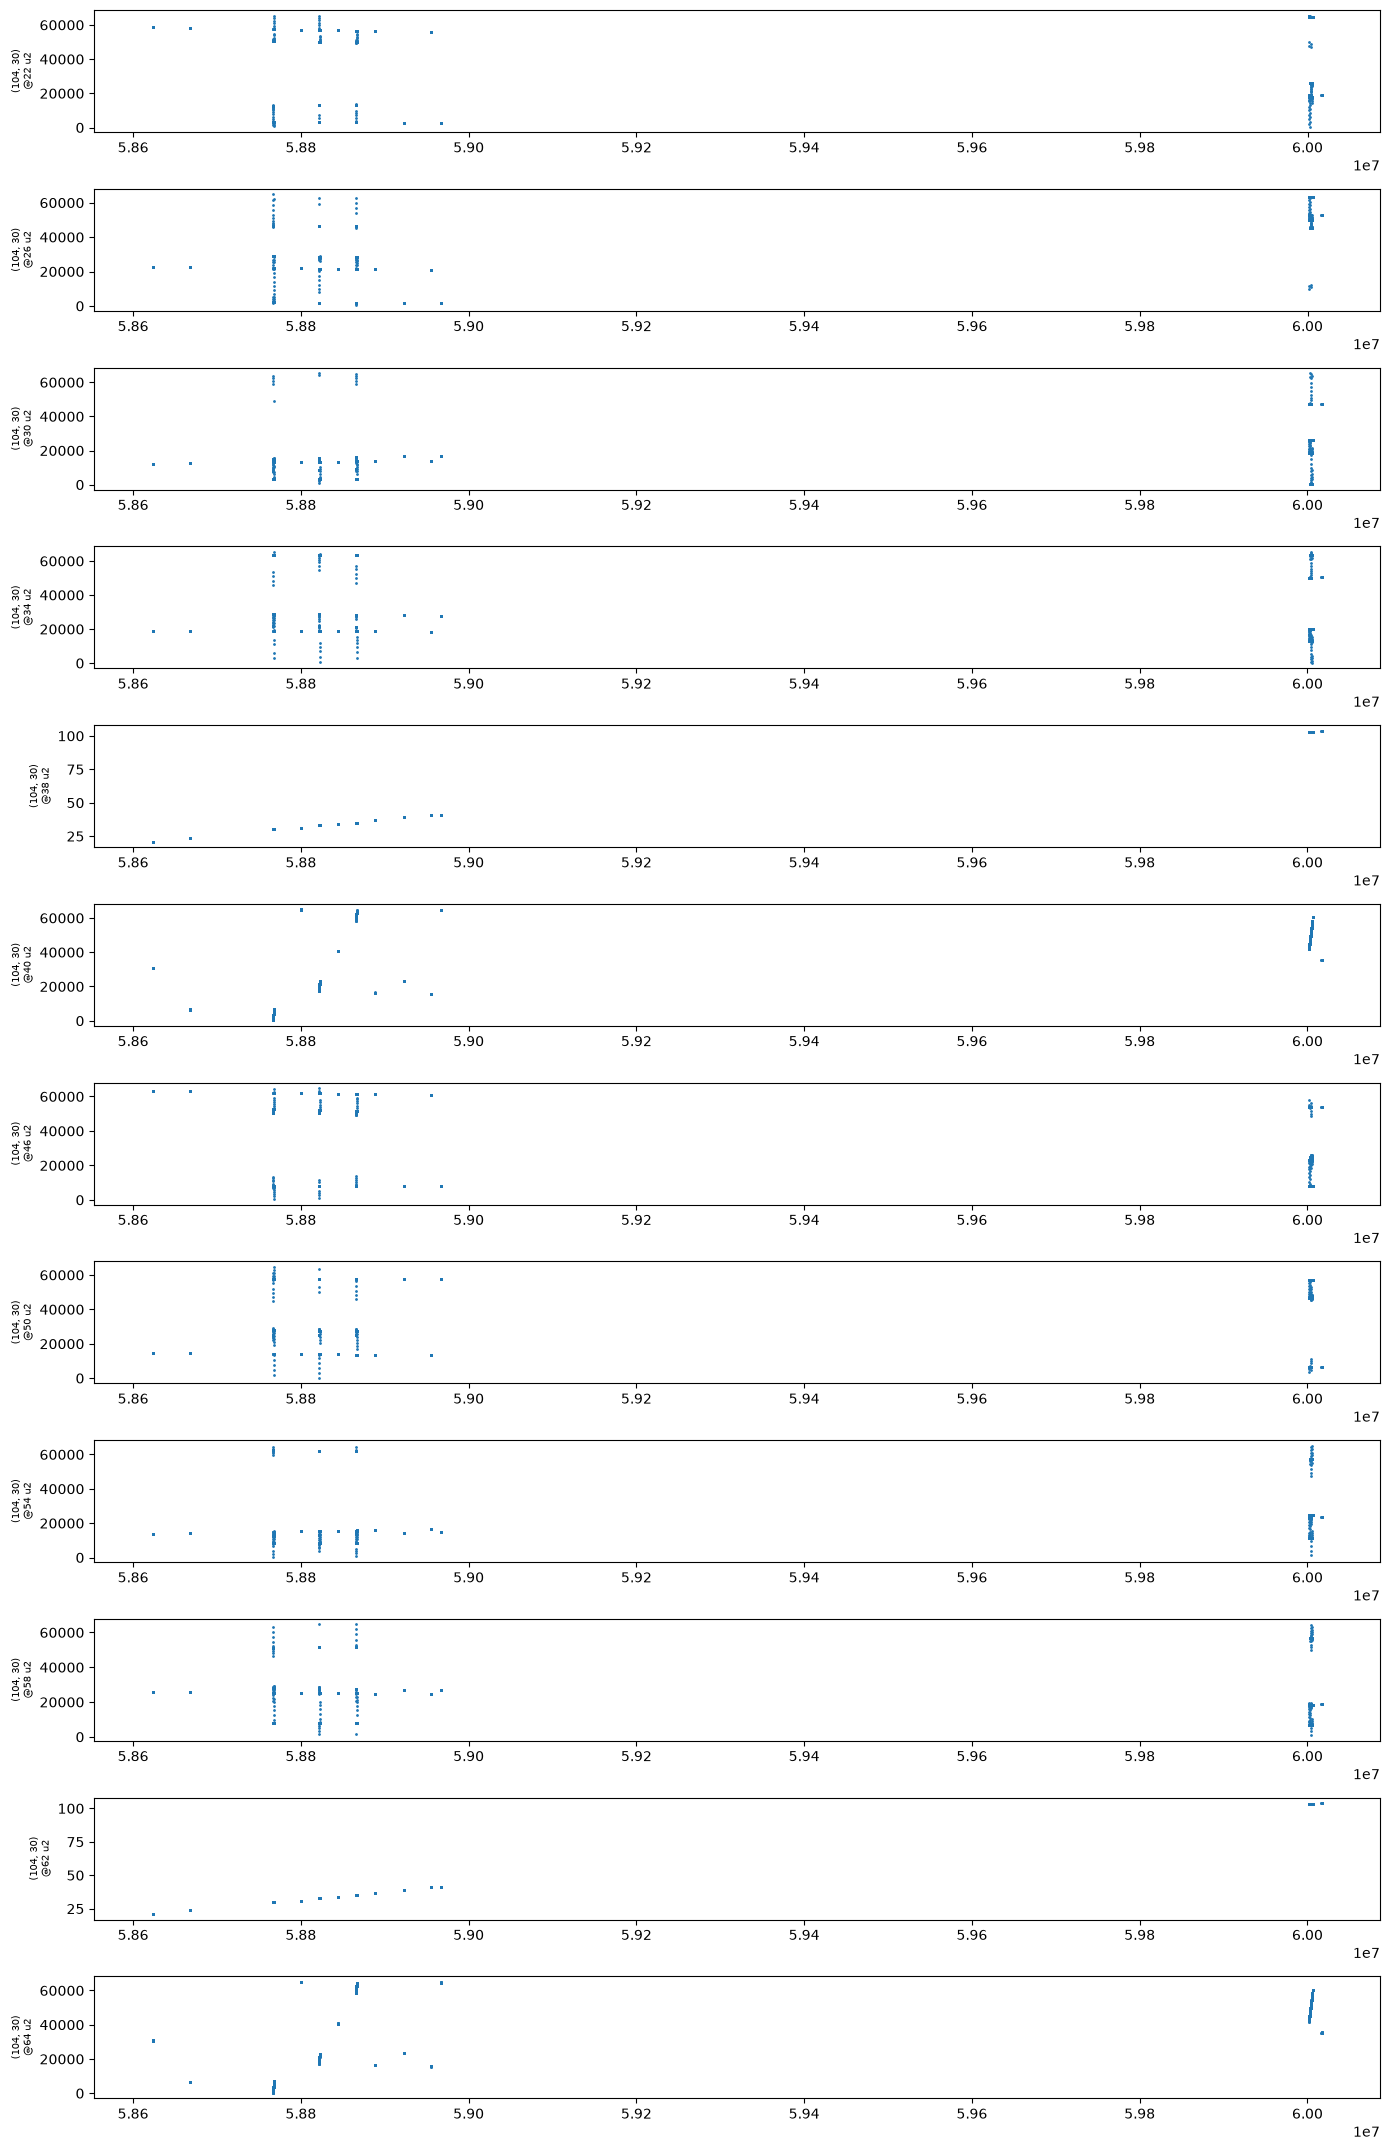

In [16]:
PLOTS = 12
chosen = [item for item in best.values() if item[0] in biggest][:PLOTS]
fig, axes = plt.subplots(len(chosen), 1, figsize=(14, 1.8 * len(chosen)))
for ax, (key, offset, name, _r, series) in zip(np.atleast_1d(axes), chosen, strict=True):
    ax.plot(to_hours(classes[key]["ticks"]), series, ".", markersize=2)
    ax.set_ylabel(f"{key}\n@{offset} {name}", fontsize=7)
fig.tight_layout()
plt.show()

## What we know so far

* APID 2 is almost entirely PUS housekeeping reports (service 3, subtype 25), plus some telecommand verification
  reports. About 120 fixed layouts, told apart by `(length, SID)`, repeating every 2 s to about 4 minutes.
* The time field is a tick counter of one second per tick (confirmed against the GPS time in `APID_18.ipynb`).
* **LYRA**: no literal match, and nothing here that is clearly a 4-channel science stream. Reports are far too
  slow for 20 Hz data (the fastest comes every 2 s), so if LYRA is in APID 2 it is its housekeeping (temperatures, voltages, integration
  time); the groups of correlated columns printed in section 7 are the candidates to check against the ICD or
  against a LYRA file from the P2SC archive. LYRA science data most likely has its own APID: look at the
  remaining ones next, for long packets at a steady high rate.
* **Attitude**: no quaternion or unit vector in float32 in any structure of this APID. The scan only covers
  big-endian float32, so fixed-point or float64 encodings would be missed.